# 02 — Elo baseline

**Goal:** look inside the tuned Elo model from `football_model.elo`, see where it does well
and badly, and compare it with the closing market line.

**Elo in econometrics terms.** Elo is an online, recursive estimator of team strength, much
like exponential smoothing. After each game:

```
R_new = R_old + K * M * (actual - expected)
```

`actual - expected` is the forecast error, and `K` is the gain: how much of that error goes into
the rating. Because a game's prediction uses only earlier games, every Elo prediction is
out-of-sample. Overfitting can only come from *choosing* K and the other settings, which is why
they were tuned on 2015–2024 (excluding 2020) and 2025 is kept as a test season.

Tuning is done by `scripts/tune_elo.py`; the defaults in `elo.EloParams` are its best settings.
This notebook makes no API calls.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm

from football_model import clean, config, elo, evaluate

pd.set_option("display.width", 200)

games = clean.load_games_table()
games = games[games["season"] <= config.TEST_SEASON]
games = evaluate.add_market_prob(games, config.TUNING_SEASONS)

params = elo.EloParams()
rated = elo.predict(games, params, config.TUNING_SEASONS)
tuning = rated[rated["season"].isin(config.TUNING_SEASONS)]
params

EloParams(k=35.0, home_field=50.0, revert=0.2, use_mov=True, initial=1500.0)

## 1. Tuning: the bias–variance trade-off in K

`reports/elo_tuning.csv` holds every grid setting. For each K, take the best log loss over
the other settings. Small K: ratings move too slowly to follow real changes (bias). Large K:
ratings chase noise from single games (variance). The best K sits between.

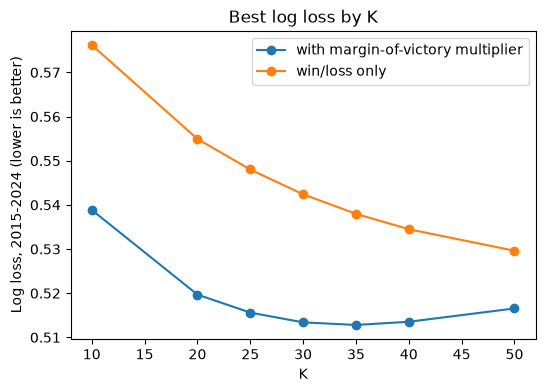

use_mov,False,True
k,,
10,0.5762,0.5389
20,0.5549,0.5197
25,0.5480,0.5156
30,0.5424,0.5134
35,0.5380,0.5128
40,0.5345,0.5135
50,0.5296,0.5165


In [2]:
grid = pd.read_csv(config.REPORTS_DIR / "elo_tuning.csv")
by_k = grid.groupby(["k", "use_mov"])["log_loss"].min().unstack()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(by_k.index, by_k[True], marker="o", label="with margin-of-victory multiplier")
ax.plot(by_k.index, by_k[False], marker="o", label="win/loss only")
ax.set_xlabel("K")
ax.set_ylabel("Log loss, 2015-2024 (lower is better)")
ax.set_title("Best log loss by K")
ax.legend()
plt.show()
by_k.round(4)

**What matters here**

- **Margin of victory helps a lot**: about 0.513 vs. 0.530 at the best K. A 35-point win
  says more about two teams than a 3-point win, and win/loss alone throws that away.
- With MOV, the curve has a clear minimum at **K ≈ 35**, and it's flat nearby (K = 30–40 are
  within 0.001). Don't read much into the exact value.
- Without MOV, log loss is still falling at K = 50, the grid's edge. That version is clearly
  worse anyway, so the grid wasn't extended for it.

## 2. Converting Elo points to points of margin

Elo works in its own units. To compare with the market's spread, regress margin on the
Elo difference (including home field), with no intercept, on the tuning seasons. This is the
same regression `elo.fit_points_per_elo` runs.

In [3]:
ols = sm.OLS(tuning["margin"], tuning["elo_diff"]).fit()
print(ols.summary().tables[1])
print(f"\n1 point of margin = {1 / ols.params['elo_diff']:.1f} Elo points")
print(f"Home field of {params.home_field:.0f} Elo = {params.home_field * ols.params['elo_diff']:.1f} points")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
elo_diff       0.0521      0.001     82.565      0.000       0.051       0.053

1 point of margin = 19.2 Elo points
Home field of 50 Elo = 2.6 points


**What matters here**

- About **19 Elo points = 1 point of margin**. A 100-point Elo edge means about a 5-point
  favorite.
- The tuned home-field advantage (50 Elo) works out to about **2.6 points**. Phase 3's
  regression will estimate home field directly, so this is a useful check.

## 3. Elo vs. the market

Scored on tuning-season games that have a closing line. Remember the market line is a
benchmark only; it is never an input.

In [4]:
table = evaluate.score_seasons(rated, "elo_prob_home", "elo_spread", config.TUNING_SEASONS)
table.round(3)

,games,model_log_loss,market_log_loss,model_brier,market_brier,model_mae,market_mae
season,,,,,,,
2015,832,0.502,0.454,0.168,0.149,13.874,12.623
2016,866,0.539,0.496,0.181,0.167,14.087,12.736
2017,873,0.528,0.471,0.179,0.154,14.098,12.396
2018,869,0.494,0.458,0.166,0.153,13.868,12.518
2019,881,0.475,0.447,0.158,0.147,13.176,11.985
2021,887,0.519,0.489,0.174,0.163,13.679,12.587
2022,892,0.555,0.497,0.188,0.168,13.655,12.184
2023,907,0.504,0.461,0.169,0.153,13.457,12.076
2024,904,0.532,0.488,0.181,0.165,13.716,11.958


**What matters here**

- Elo's log loss is about **0.517 against the market's 0.474**, and its MAE is about
  **13.7 points against 12.3**. Losing to the market is normal: the closing line knows
  about injuries, quarterback changes, and everything else that happened that week.
- The gap is fairly steady from season to season, so this isn't one bad year.

## 4. Calibration

In [5]:
calib = evaluate.calibration_plot(
    tuning["home_win"],
    tuning["elo_prob_home"],
    config.FIGURES_DIR / "elo_calibration.png",
    title="Elo calibration, 2015-2024",
)
calib.round(3)

,bin,predicted,actual,games
0,"(-0.001, 0.1]",0.068,0.083,168
1,"(0.1, 0.2]",0.153,0.182,457
2,"(0.2, 0.3]",0.251,0.280,628
3,"(0.3, 0.4]",0.352,0.391,724
4,"(0.4, 0.5]",0.450,0.488,775
5,"(0.5, 0.6]",0.550,0.558,865
6,"(0.6, 0.7]",0.651,0.636,883
7,"(0.7, 0.8]",0.752,0.751,970
8,"(0.8, 0.9]",0.853,0.849,1052
9,"(0.9, 1.0]",0.952,0.945,1479


![Elo calibration](../reports/figures/elo_calibration.png)

**What matters here**

- The points sit close to the 45° line, so Elo's probabilities are honest on average.
- At the low end, home underdogs win slightly **more** than Elo predicts (Elo gives 7%, they
  win about 8.5%; Elo gives 35%, they win about 39%). Phase 4 can fix this kind of small bias
  with a recalibration step.

## 5. Where does Elo lose to the market? By week of the season

Regular season only; weeks 13 and later are grouped together.

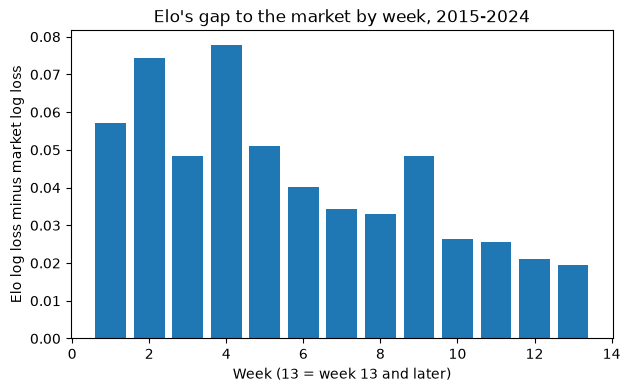

,games,elo,market,gap
week_group,,,,
1,754.0,0.383,0.326,0.057
2,687.0,0.427,0.353,0.074
3,612.0,0.431,0.383,0.048
4,559.0,0.535,0.457,0.078
5,525.0,0.526,0.475,0.051
6,480.0,0.580,0.540,0.040
7,490.0,0.589,0.554,0.034
8,505.0,0.554,0.521,0.033
9,486.0,0.587,0.539,0.048


In [6]:
regular = tuning[(tuning["season_type"] == "regular") & tuning["market_spread"].notna()]
regular = regular.assign(week_group=regular["week"].clip(upper=13))

by_week = regular.groupby("week_group").apply(
    lambda d: pd.Series(
        {
            "games": len(d),
            "elo": evaluate.log_loss(d["home_win"], d["elo_prob_home"]),
            "market": evaluate.log_loss(d["home_win"], d["market_prob_home"]),
        }
    ),
    include_groups=False,
)
by_week["gap"] = by_week["elo"] - by_week["market"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_week.index, by_week["gap"])
ax.set_xlabel("Week (13 = week 13 and later)")
ax.set_ylabel("Elo log loss minus market log loss")
ax.set_title("Elo's gap to the market by week, 2015-2024")
plt.show()
by_week.round(3)

**What matters here**

- **The gap is biggest in weeks 1–4** (about 0.05–0.08) and shrinks to about 0.02–0.03
  later. Early in the season, Elo's only information is last year's rating pulled 20% toward
  the mean. The market also knows about returning starters, transfers, recruiting, and coaching
  changes.
- That points to the biggest gain available: **better preseason ratings** (recruiting,
  returning production; Phase 5). Phase 3's ridge model, with a prior from last season, is
  the next step.
- Absolute log loss is lowest in weeks 1–3 for both models, because those weeks have many
  lopsided FBS-vs-FCS games that are easy to call.

## 6. Ratings over time

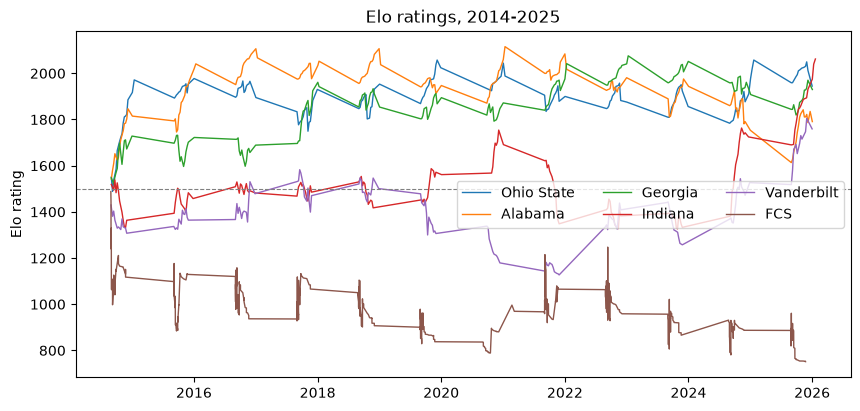

In [7]:
def team_history(rated_games: pd.DataFrame, team: str) -> pd.DataFrame:
    """Post-game rating after each of a team's games."""
    home = rated_games.loc[rated_games["home_team"] == team, ["start_date", "home_elo_post"]]
    away = rated_games.loc[rated_games["away_team"] == team, ["start_date", "away_elo_post"]]
    history = pd.concat(
        [home.set_axis(["date", "rating"], axis=1), away.set_axis(["date", "rating"], axis=1)]
    )
    return history.sort_values("date")


fig, ax = plt.subplots(figsize=(10, 4.5))
for team in ["Ohio State", "Alabama", "Georgia", "Indiana", "Vanderbilt", "FCS"]:
    history = team_history(rated, team)
    ax.plot(history["date"], history["rating"], label=team, linewidth=1)
ax.axhline(1500, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Elo rating")
ax.set_title("Elo ratings, 2014-2025")
ax.legend(ncol=3)
plt.show()

In [8]:
# End of the 2024 season (the last tuning season)
elo.final_ratings(rated[rated["season"] <= 2024]).head(15).round({"rating": 0})

,team,rating,last_game
0,Ohio State,2057.0,2025-01-21 00:30:00+00:00
1,Notre Dame,1949.0,2025-01-21 00:30:00+00:00
2,Oregon,1918.0,2025-01-01 22:00:00+00:00
3,Georgia,1908.0,2025-01-02 21:00:00+00:00
4,Texas,1896.0,2025-01-11 00:30:00+00:00
5,Penn State,1876.0,2025-01-10 00:30:00+00:00
6,Ole Miss,1839.0,2025-01-03 01:00:00+00:00
7,Michigan,1799.0,2024-12-31 17:00:00+00:00
8,Tennessee,1756.0,2024-12-22 01:00:00+00:00
9,Alabama,1753.0,2024-12-31 17:00:00+00:00


**What matters here**

- The steps at each season boundary are the 20% pull toward the mean.
- The shared **FCS** team settles far below 1500, at around 900. As an average FCS opponent it
  loses most games to FBS teams, which is what we want.
- The end-of-2024 top of the table (Ohio State, Notre Dame, Oregon, Georgia, Texas, Penn
  State) matches the 2024 playoff field, which is a good sanity check.

## 7. Summary

| | Elo | Market |
| --- | --- | --- |
| Log loss, 2015–2024 | ≈ 0.517 | ≈ 0.474 |
| Brier, 2015–2024 | ≈ 0.174 | ≈ 0.158 |
| MAE (points), 2015–2024 | ≈ 13.7 | ≈ 12.3 |

Tuned settings: K = 35, home field = 50 Elo (≈ 2.6 points), 20% reversion to the mean
between seasons, margin-of-victory multiplier on.

**Baseline for Phase 3:** the ridge spread model must beat Elo's log loss of 0.517 and MAE of 13.7
on the same seasons. The largest room to improve is early in the season.